# Влияние SMS на конверсию в покупку

Сравниваю конверсию у клиентов, назначенных в группу SMS, и контрольной группы. Метрика — число покупателей среди всех клиентов группы, эффект — разница B−A.

Учебный анализ на открытых данных завершённого эксперимента [X5 RetailHero](https://ods.ai/competitions/x5-retailhero-uplift-modeling/data). В файле есть идентификатор клиента, назначенная группа и факт покупки. Параметры расчёта выборки описаны в [дизайне эксперимента](experiment_design.md).

In [1]:
from hashlib import sha256
from pathlib import Path
from urllib.request import urlretrieve
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chisquare, norm
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    proportion_confint,
    proportion_effectsize,
    proportions_ztest,
)

root = Path.cwd()
data_path = root / "data/uplift_train.csv.gz"
source_url = "https://sklift.s3.eu-west-2.amazonaws.com/uplift_train.csv.gz"
for folder in ["data", "results", "figures"]:
    (root / folder).mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## Проверка данных

`client_id` — клиент, `treatment_flg` — группа (0 — контроль A, 1 — SMS B), `target` — покупка. Проверяю, что каждому клиенту соответствует одна строка, а группа и исход заданы без пропусков и принимают значения 0 или 1.

In [2]:
if not data_path.exists():
    urlretrieve(source_url, data_path)

users = pd.read_csv(data_path, dtype={"client_id": "string"})
required = ["client_id", "treatment_flg", "target"]
missing_columns = set(required) - set(users.columns)
if missing_columns:
    raise ValueError(f"Не хватает колонок: {missing_columns}")
users = users[required]
source_hash = sha256(data_path.read_bytes()).hexdigest()

checks = pd.DataFrame([
    ("rows", len(users)),
    ("unique_client_id", users["client_id"].nunique()),
    ("duplicate_client_id", users["client_id"].duplicated().sum()),
    *[(f"missing_{column}", users[column].isna().sum()) for column in required],
    ("invalid_treatment_flg", (~users["treatment_flg"].isin([0, 1])).sum()),
    ("invalid_target", (~users["target"].isin([0, 1])).sum()),
], columns=["check", "value"])
display(checks)

sizes = users.groupby("treatment_flg").size()
display(sizes.rename("clients").to_frame())
errors = checks.loc[~checks["check"].isin(["rows", "unique_client_id"]), "value"].sum()
if errors or set(sizes.index) != {0, 1}:
    raise ValueError("Есть пропуски, повторы или некорректные группы: проверьте данные.")
n_a = int(sizes[0])
n_b = int(sizes[1])

,check,value
0,rows,200039
1,unique_client_id,200039
2,duplicate_client_id,0
3,missing_client_id,0
4,missing_treatment_flg,0
5,missing_target,0
6,invalid_treatment_flg,0
7,invalid_target,0


,clients
treatment_flg,
0,100058
1,99981


В выборке 200 039 клиентов: 100 058 в контроле и 99 981 в группе SMS. Пропусков, повторов клиентов и значений вне 0/1 нет. Все строки оставляю в анализе.

## Размер выборки

Основная гипотеза: H0 — pB≤pA, H1 — pB>pA. Для расчёта беру базовую конверсию 50%, эффект +1 п.п., alpha=0.05, мощность 80% и равные группы. Переход 50% → 51% соответствует относительному росту 2%.

Сравниваю сценарии с базовой конверсией 30%, 50% и 70%, эффектами 0.5, 1 и 2 п.п. и мощностью 80% и 90%. Размер группы рассчитываю через Cohen's h в `NormalIndPower`. Дополнительно сравниваю с нормальным приближением:

\[
n \approx \frac{[z_{1-\alpha}\sqrt{2\bar p(1-\bar p)}+z_{power}\sqrt{p_0(1-p_0)+p_1(1-p_1)}]^2}{\delta^2},
\]

где p1=p0+δ, p̄=(p0+p1)/2. Оба расчёта приближённые; выбранный z-тест ниже проверяю симуляциями.

In [3]:
alpha = 0.05
target_power = 0.80
p0 = 0.50
delta = 0.01
power_test = NormalIndPower()


def sample_size(base, effect, power):
    h = proportion_effectsize(base + effect, base)
    n = power_test.solve_power(
        effect_size=h, alpha=alpha, power=power, ratio=1, alternative="larger"
    )
    return math.ceil(n)


def normal_sample_size(base, effect, power):
    p1 = base + effect
    average = (base + p1) / 2
    null_term = norm.ppf(1 - alpha) * np.sqrt(2 * average * (1 - average))
    effect_term = norm.ppf(power) * np.sqrt(base * (1 - base) + p1 * (1 - p1))
    return math.ceil((null_term + effect_term)**2 / effect**2)


planning_rows = []
for base in [0.30, 0.50, 0.70]:
    for effect in [0.005, 0.01, 0.02]:
        for power in [0.80, 0.90]:
            n = sample_size(base, effect, power)
            planning_rows.append({
                "p0": base, "delta": effect, "delta_pp": effect * 100,
                "power": power, "n_per_group": n, "n_total": 2 * n,
                "n_normal": normal_sample_size(base, effect, power), "alpha": alpha,
            })

planning = pd.DataFrame(planning_rows)
display(planning)
n_sim = sample_size(p0, delta, target_power)
print(f"Основной сценарий: {n_sim:,} клиентов на группу, всего {2 * n_sim:,}.")

,p0,delta,delta_pp,power,n_per_group,n_total,n_normal,alpha
0,0.3,0.005,0.5,0.8,104357,208714,104358,0.05
1,0.3,0.005,0.5,0.9,144552,289104,144552,0.05
2,0.3,0.010,1.0,0.8,26210,52420,26210,0.05
3,0.3,0.010,1.0,0.9,36305,72610,36305,0.05
4,0.3,0.020,2.0,0.8,6611,13222,6612,0.05
5,0.3,0.020,2.0,0.9,9157,18314,9158,0.05
6,0.5,0.005,0.5,0.8,123648,247296,123648,0.05
7,0.5,0.005,0.5,0.9,171272,342544,171271,0.05
8,0.5,0.010,1.0,0.8,30909,61818,30909,0.05
9,0.5,0.010,1.0,0.9,42814,85628,42814,0.05


Основной сценарий: 30,909 клиентов на группу, всего 61,818.


Для эффекта +1 п.п. при мощности 80% нужно 30 909 клиентов на группу; при 90% — 42 814. Если уменьшить эффект до 0.5 п.п., нужно 123 648 клиентов на группу — примерно вчетверо больше.

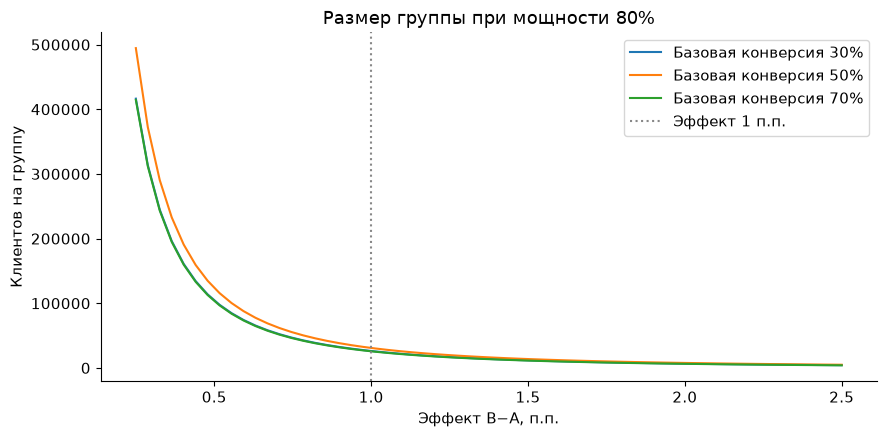

In [4]:
effects = np.linspace(0.0025, 0.025, 60)
fig, ax = plt.subplots()
for base in [0.3, 0.5, 0.7]:
    group_sizes = [sample_size(base, effect, target_power) for effect in effects]
    ax.plot(effects * 100, group_sizes, label=f"Базовая конверсия {base:.0%}")
ax.axvline(delta * 100, color="#888888", linestyle=":", label="Эффект 1 п.п.")
ax.set(
    xlabel="Эффект B−A, п.п.", ylabel="Клиентов на группу",
    title="Размер группы при мощности 80%",
)
ax.legend()
fig.tight_layout()
fig.savefig(root / "figures/sample_size.png", dpi=160)
plt.show()

### Обнаружимый эффект при доступном размере

Для фактических размеров групп нахожу MDE при мощности 80% и тех же базовых конверсиях. В расчёте первая группа — B, поэтому `nobs1=n_b`, `ratio=n_a/n_b`. Обратное преобразование Cohen's h даёт p1=sin²(arcsin(√p0)+h/2).

In [5]:
h_available = power_test.solve_power(
    effect_size=None, nobs1=n_b, alpha=alpha, power=target_power,
    ratio=n_a / n_b, alternative="larger",
)
available = pd.DataFrame([
    {
        "p0": base, "n_a": n_a, "n_b": n_b, "alpha": alpha,
        "power": target_power,
        "mde": np.sin(np.arcsin(np.sqrt(base)) + h_available / 2)**2 - base,
    }
    for base in [0.3, 0.5, 0.7]
])
available["mde_pp"] = available["mde"] * 100
display(available.round(4))

,p0,n_a,n_b,alpha,power,mde,mde_pp
0,0.3,100058,99981,0.05,0.8,0.0051,0.5107
1,0.5,100058,99981,0.05,0.8,0.0056,0.5559
2,0.7,100058,99981,0.05,0.8,0.0051,0.5082


При базовой конверсии 50% доступные группы позволяют обнаружить эффект около 0,556 п.п. с мощностью 80%. Этот расчёт характеризует чувствительность при заданном сценарии.

## Проверка A/A

Генерирую по 5000 независимых пар групп с конверсией 50% и рассчитанным размером. Число покупок беру из биномиального распределения: это позволяет моделировать бинарные исходы без создания строк для каждого клиента.

Во всех сравнениях использую один pooled z-тест. Группа B идёт первой, `alternative="larger"` задаёт направление B−A. Долю ложных срабатываний сравниваю с alpha=5%; интервал Wilson показывает неопределённость этой доли при 5000 повторениях.

In [6]:
repeats = 5000


def z_test(buyers_b, total_b, buyers_a, total_a):
    return proportions_ztest(
        count=[buyers_b, buyers_a], nobs=[total_b, total_a],
        value=0, alternative="larger", prop_var=False,
    )


def simulate_pvalues(rng, effect):
    buyers_a = rng.binomial(n_sim, p0, repeats)
    buyers_b = rng.binomial(n_sim, p0 + effect, repeats)
    return np.array([
        z_test(b, n_sim, a, n_sim)[1]
        for a, b in zip(buyers_a, buyers_b)
    ])


aa_pvalues = simulate_pvalues(np.random.default_rng(42), 0)
aa_rejected = int((aa_pvalues < alpha).sum())
aa_low, aa_high = proportion_confint(aa_rejected, repeats, alpha=0.05, method="wilson")
print(f"Ложные срабатывания: {aa_rejected} из {repeats} ({aa_rejected / repeats:.2%}).")
print(f"95% интервал Wilson: [{aa_low:.2%}; {aa_high:.2%}].")

edges = np.linspace(0, 1, 21)

Ложные срабатывания: 234 из 5000 (4.68%).
95% интервал Wilson: [4.13%; 5.30%].


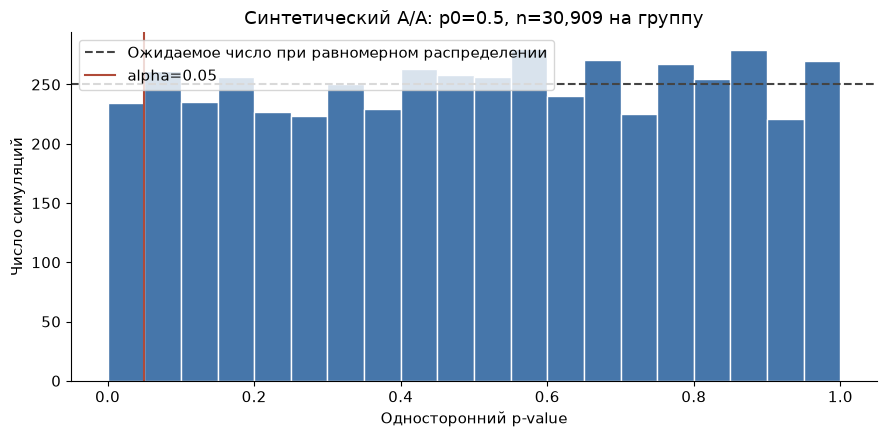

In [7]:
fig, ax = plt.subplots()
ax.hist(aa_pvalues, bins=edges, color="#4676aa", edgecolor="white")
ax.axhline(
    repeats / 20, linestyle="--", color="#444444",
    label="Ожидаемое число при равномерном распределении",
)
ax.axvline(alpha, color="#b04a38", label="alpha=0.05")
ax.set(
    xlabel="Односторонний p-value", ylabel="Число симуляций",
    title=f"Синтетический A/A: p0=0.5, n={n_sim:,} на группу",
)
ax.legend()
fig.tight_layout()
fig.savefig(root / "figures/aa_pvalues.png", dpi=160)
plt.show()

В A/A получилось 234 ложных срабатывания из 5000 — 4,68%. Заданные 5% входят в 95% интервал [4,13%; 5,30%]. Частота ошибок согласуется с выбранным уровнем значимости в этой симуляции.

## Проверка мощности A/B

Оставляю pA=0.5 и задаю несколько положительных эффектов для B. Для каждого эффекта генерирую 5000 новых пар групп. Эмпирическую мощность считаю как долю отклонений H0 и сравниваю с аналитическим расчётом.

In [8]:
rng_ab = np.random.default_rng(43)
power_rows = []
for effect in [0, 0.0025, 0.005, 0.0075, 0.01, 0.0125, 0.015, 0.02]:
    pvalues = simulate_pvalues(rng_ab, effect)
    rejected = int((pvalues < alpha).sum())
    low, high = proportion_confint(rejected, repeats, alpha=0.05, method="wilson")
    analytical_power = power_test.power(
        effect_size=proportion_effectsize(p0 + effect, p0), nobs1=n_sim,
        alpha=alpha, ratio=1, alternative="larger",
    )
    power_rows.append({
        "p0": p0, "delta": effect, "delta_pp": effect * 100,
        "n_per_group": n_sim, "repeats": repeats, "seed": 43, "alpha": alpha,
        "rejected": rejected, "empirical_power": rejected / repeats,
        "ci_lower": low, "ci_upper": high, "analytical_power": analytical_power,
    })

sim_power = pd.DataFrame(power_rows)
display(sim_power[
    ["delta_pp", "empirical_power", "ci_lower", "ci_upper", "analytical_power"]
].round(4))

,delta_pp,empirical_power,ci_lower,ci_upper,analytical_power
0,0.00,0.0462,0.0407,0.0524,0.0500
1,0.25,0.1534,0.1437,0.1637,0.1531
2,0.50,0.3400,0.3270,0.3532,0.3440
3,0.75,0.5872,0.5735,0.6008,0.5870
4,1.00,0.7994,0.7881,0.8103,0.8000
5,1.25,0.9252,0.9176,0.9322,0.9283
6,1.50,0.9842,0.9804,0.9873,0.9815
7,2.00,0.9992,0.9979,0.9997,0.9996


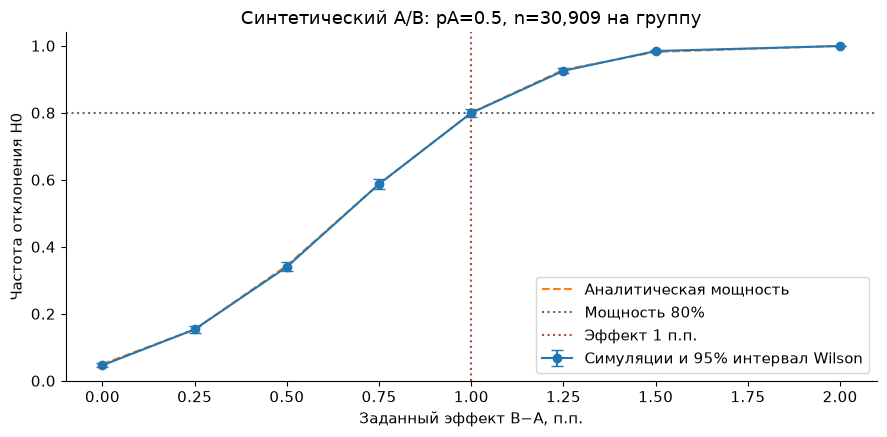

In [9]:
fig, ax = plt.subplots()
ax.errorbar(
    sim_power["delta_pp"], sim_power["empirical_power"],
    yerr=[
        sim_power["empirical_power"] - sim_power["ci_lower"],
        sim_power["ci_upper"] - sim_power["empirical_power"],
    ],
    fmt="o-", capsize=4, label="Симуляции и 95% интервал Wilson",
)
ax.plot(
    sim_power["delta_pp"], sim_power["analytical_power"], "--",
    label="Аналитическая мощность",
)
ax.axhline(target_power, color="#666666", linestyle=":", label="Мощность 80%")
ax.axvline(delta * 100, color="#b04a38", linestyle=":", label="Эффект 1 п.п.")
ax.set(
    xlabel="Заданный эффект B−A, п.п.", ylabel="Частота отклонения H0",
    ylim=(0, 1.04), title=f"Синтетический A/B: pA=0.5, n={n_sim:,} на группу",
)
ax.legend()
fig.tight_layout()
fig.savefig(root / "figures/power_curve.png", dpi=160)
plt.show()

При эффекте +1 п.п. эмпирическая мощность — 79,94%, аналитическая — 80,00%. Аналитическая оценка входит в 95% интервал симуляций [78,81%; 81,03%]. Рассчитанный размер группы даёт мощность, близкую к целевым 80%.

## Сравнение конверсий

Считаю конверсии по всем клиентам в исходных группах. В `target` записана покупка за период, длительность которого в файле не указана.

In [10]:
groups = users.groupby("treatment_flg").agg(
    clients=("client_id", "size"),
    buyers=("target", "sum"),
    conversion=("target", "mean"),
)
buyers_a = int(groups.loc[0, "buyers"])
buyers_b = int(groups.loc[1, "buyers"])
p_a = float(groups.loc[0, "conversion"])
p_b = float(groups.loc[1, "conversion"])
effect = p_b - p_a
relative_lift = effect / p_a * 100

groups = groups.reset_index()
groups.insert(0, "group", groups["treatment_flg"].map({0: "A", 1: "B"}))
display(groups.round(4))
groups.to_csv(root / "results/group_summary.csv", index=False)

,group,treatment_flg,clients,buyers,conversion
0,A,0,100058,60363,0.6033
1,B,1,99981,63639,0.6365


### Проверка гипотезы и доверительные границы

Применяю односторонний z-тест к разнице B−A. Для оценки величины эффекта строю двусторонний 95% score-интервал. Нижнюю одностороннюю 95% границу получаю как нижний конец двустороннего 90% score-интервала; она соответствует направлению основного теста.

In [11]:
z_value, p_value = z_test(buyers_b, n_b, buyers_a, n_a)
ci_lower, ci_upper = confint_proportions_2indep(
    buyers_b, n_b, buyers_a, n_a,
    compare="diff", method="score", alpha=0.05, correction=False,
)
lower95 = confint_proportions_2indep(
    buyers_b, n_b, buyers_a, n_a,
    compare="diff", method="score", alpha=0.10, correction=False,
)[0]

print(f"Конверсия A: {p_a:.3%}; B: {p_b:.3%}.")
print(f"Разница B−A: {effect * 100:.3f} п.п.; относительный рост: {relative_lift:.2f}%.")
print(f"Односторонний z-тест: z={z_value:.3f}, p-value={p_value:.3e}.")
print(f"Двусторонний 95% score-интервал: [{ci_lower * 100:.3f}; {ci_upper * 100:.3f}] п.п.")
print(f"Нижняя односторонняя 95% граница: {lower95 * 100:.3f} п.п.")
print(f"Средний прирост на 1000 клиентов B: {effect * 1000:.1f} покупателя.")

Конверсия A: 60.328%; B: 63.651%.
Разница B−A: 3.323 п.п.; относительный рост: 5.51%.
Односторонний z-тест: z=15.309, p-value=3.312e-53.
Двусторонний 95% score-интервал: [2.898; 3.748] п.п.
Нижняя односторонняя 95% граница: 2.966 п.п.
Средний прирост на 1000 клиентов B: 33.2 покупателя.


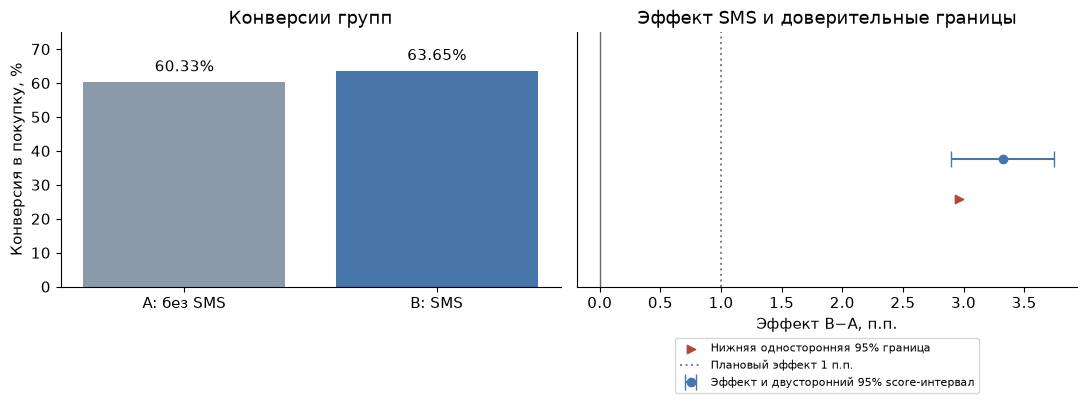

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))
bars = ax1.bar(
    ["A: без SMS", "B: SMS"], [p_a * 100, p_b * 100], color=["#8a9aa8", "#4676aa"]
)
ax1.bar_label(bars, fmt="%.2f%%", padding=5)
ax1.set(ylabel="Конверсия в покупку, %", ylim=(0, 75), title="Конверсии групп")
ax2.errorbar(
    [effect * 100], [0],
    xerr=[[100 * (effect - ci_lower)], [100 * (ci_upper - effect)]],
    fmt="o", capsize=6, color="#4676aa", label="Эффект и двусторонний 95% score-интервал",
)
ax2.scatter(
    [lower95 * 100], [-0.25], marker=">", color="#b04a38",
    label="Нижняя односторонняя 95% граница",
)
ax2.axvline(0, color="#666666", linewidth=1)
ax2.axvline(delta * 100, color="#888888", linestyle=":", label="Плановый эффект 1 п.п.")
ax2.set(
    xlabel="Эффект B−A, п.п.", yticks=[], ylim=(-0.8, 0.8),
    title="Эффект SMS и доверительные границы",
)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8)
fig.tight_layout()
fig.savefig(root / "figures/experiment_result.png", dpi=160, bbox_inches="tight")
plt.show()

Конверсия выросла с 60,328% до 63,651%: разница +3,323 п.п., относительный рост 5,51%. При p-value=3,31×10⁻⁵³ отклоняю H0 в пользу роста конверсии. Двусторонний 95% интервал эффекта [2,898; 3,748] п.п. лежит выше нуля и планового эффекта 1 п.п.; основной тест при этом проверяет рост относительно нуля.

### Размеры групп

Проверяю SRM критерием χ² относительно равного распределения 50/50. Исходное целевое распределение неизвестно, поэтому использую проверку как диагностику размеров групп.

In [13]:
srm_stat, srm_p_value = chisquare([n_a, n_b], f_exp=[(n_a + n_b) / 2] * 2)
print(f"SRM относительно 50/50: chi²={srm_stat:.3f}, p-value={srm_p_value:.3f}.")

SRM относительно 50/50: chi²=0.030, p-value=0.863.


p-value=0,863: статистически значимого отклонения числа клиентов от 50/50 нет.

## Вывод

Конверсия в группе SMS — 63,651% против 60,328% в контроле. Разница +3,323 п.п., двусторонний 95% score-интервал — [2,898; 3,748] п.п. Это оценка около 33 дополнительных покупателей на 1000 клиентов группы SMS.

Следующий расчёт — покрывает ли дополнительная маржа расходы на коммуникацию. На одного клиента группы B условие окупаемости: `effect * m - c > 0`, где `effect` — рассчитанная разница конверсий в долях, `m` — дополнительная маржа на привлечённого покупателя, `c` — средние расходы на коммуникацию на клиента B. Стоимости, маржи, доставки и отписок в CSV нет; фактическую прибыль здесь не рассчитываю.

## Выгрузка в PostgreSQL

CSV в `results/` использует загрузчик PostgreSQL. Сохраняю итоговые оценки и хеш исходного файла, чтобы загрузчик мог сверить данные с расчётами. Запуск и дашборд описаны в [инструкции Redash](redash_setup.md).

In [14]:
summary = pd.DataFrame([{
    "n_a": n_a, "n_b": n_b, "n_total": n_a + n_b,
    "buyers_a": buyers_a, "buyers_b": buyers_b, "buyers_total": buyers_a + buyers_b,
    "p_a": p_a, "p_b": p_b, "effect": effect, "effect_pp": effect * 100,
    "relative_lift_pct": relative_lift, "z_stat": z_value, "p_value": p_value,
    "lower_one_sided95": lower95, "ci_lower95": ci_lower, "ci_upper95": ci_upper,
    "alpha": alpha, "srm_stat": srm_stat, "srm_p_value": srm_p_value,
}])
summary.to_csv(root / "results/experiment_summary.csv", index=False)

metadata = {"source_url": source_url, "source_sha256": source_hash}
(root / "results/analysis_metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2) + "\n"
)
print("Расчётные таблицы сохранены в results/.")

Расчётные таблицы сохранены в results/.
